## 딥러닝 1 예습 정리

### 목차
1. 합성곱 신경망 (CNN)
2. 이미지 딥러닝 응용
3. 순환 신경망 (RNN)
4. LSTM & GRU
5. Seq2Seq

---

### 1. 합성곱 신경망 (CNN)

#### 1-1. 픽셀과 채널

- **픽셀**  
: 이미지를 구성하는 가장 기본적인 단위
    - 특정 위치의 색상 또는 밝기 정보 보유
    - 흑백 이미지 = 2차원 배열 = (세로 픽셀 수 × 가로 픽셀 수)
    - 값 범위: 일반적으로 `0 ~ 255`

- **채널**  
: 이미지의 색상 정보를 구성하는 데이터 층
    - **흑백:** 밝기 값만 필요 → 채널 1개
    - **컬러:** 빨강, 초록, 파랑 값 필요 → 채널 3개 

- **색공간**  
: 색상을 숫자로 표현하는 체계
    - **그레이 스케일:** 밝기만 표현
        - 명도 값 범위: 일반적으로 `0 ~ 255`
        - 채널 값 = 1
        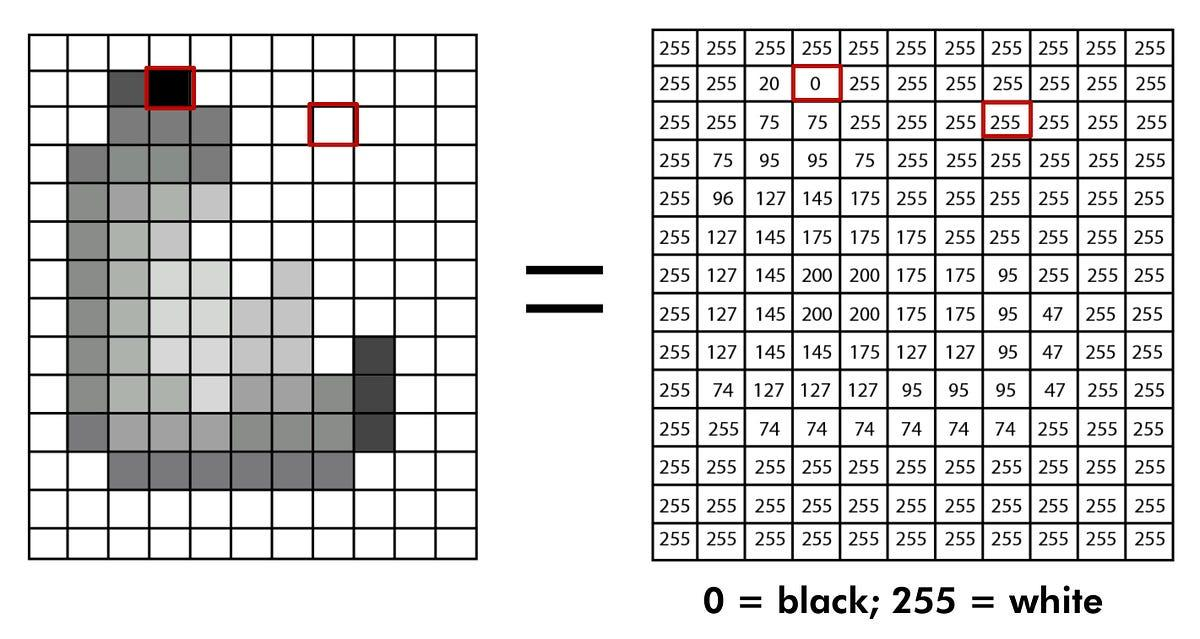
    - **RGB:** 빨강, 초록, 파랑의 조합
        - 채널 값 = 3
        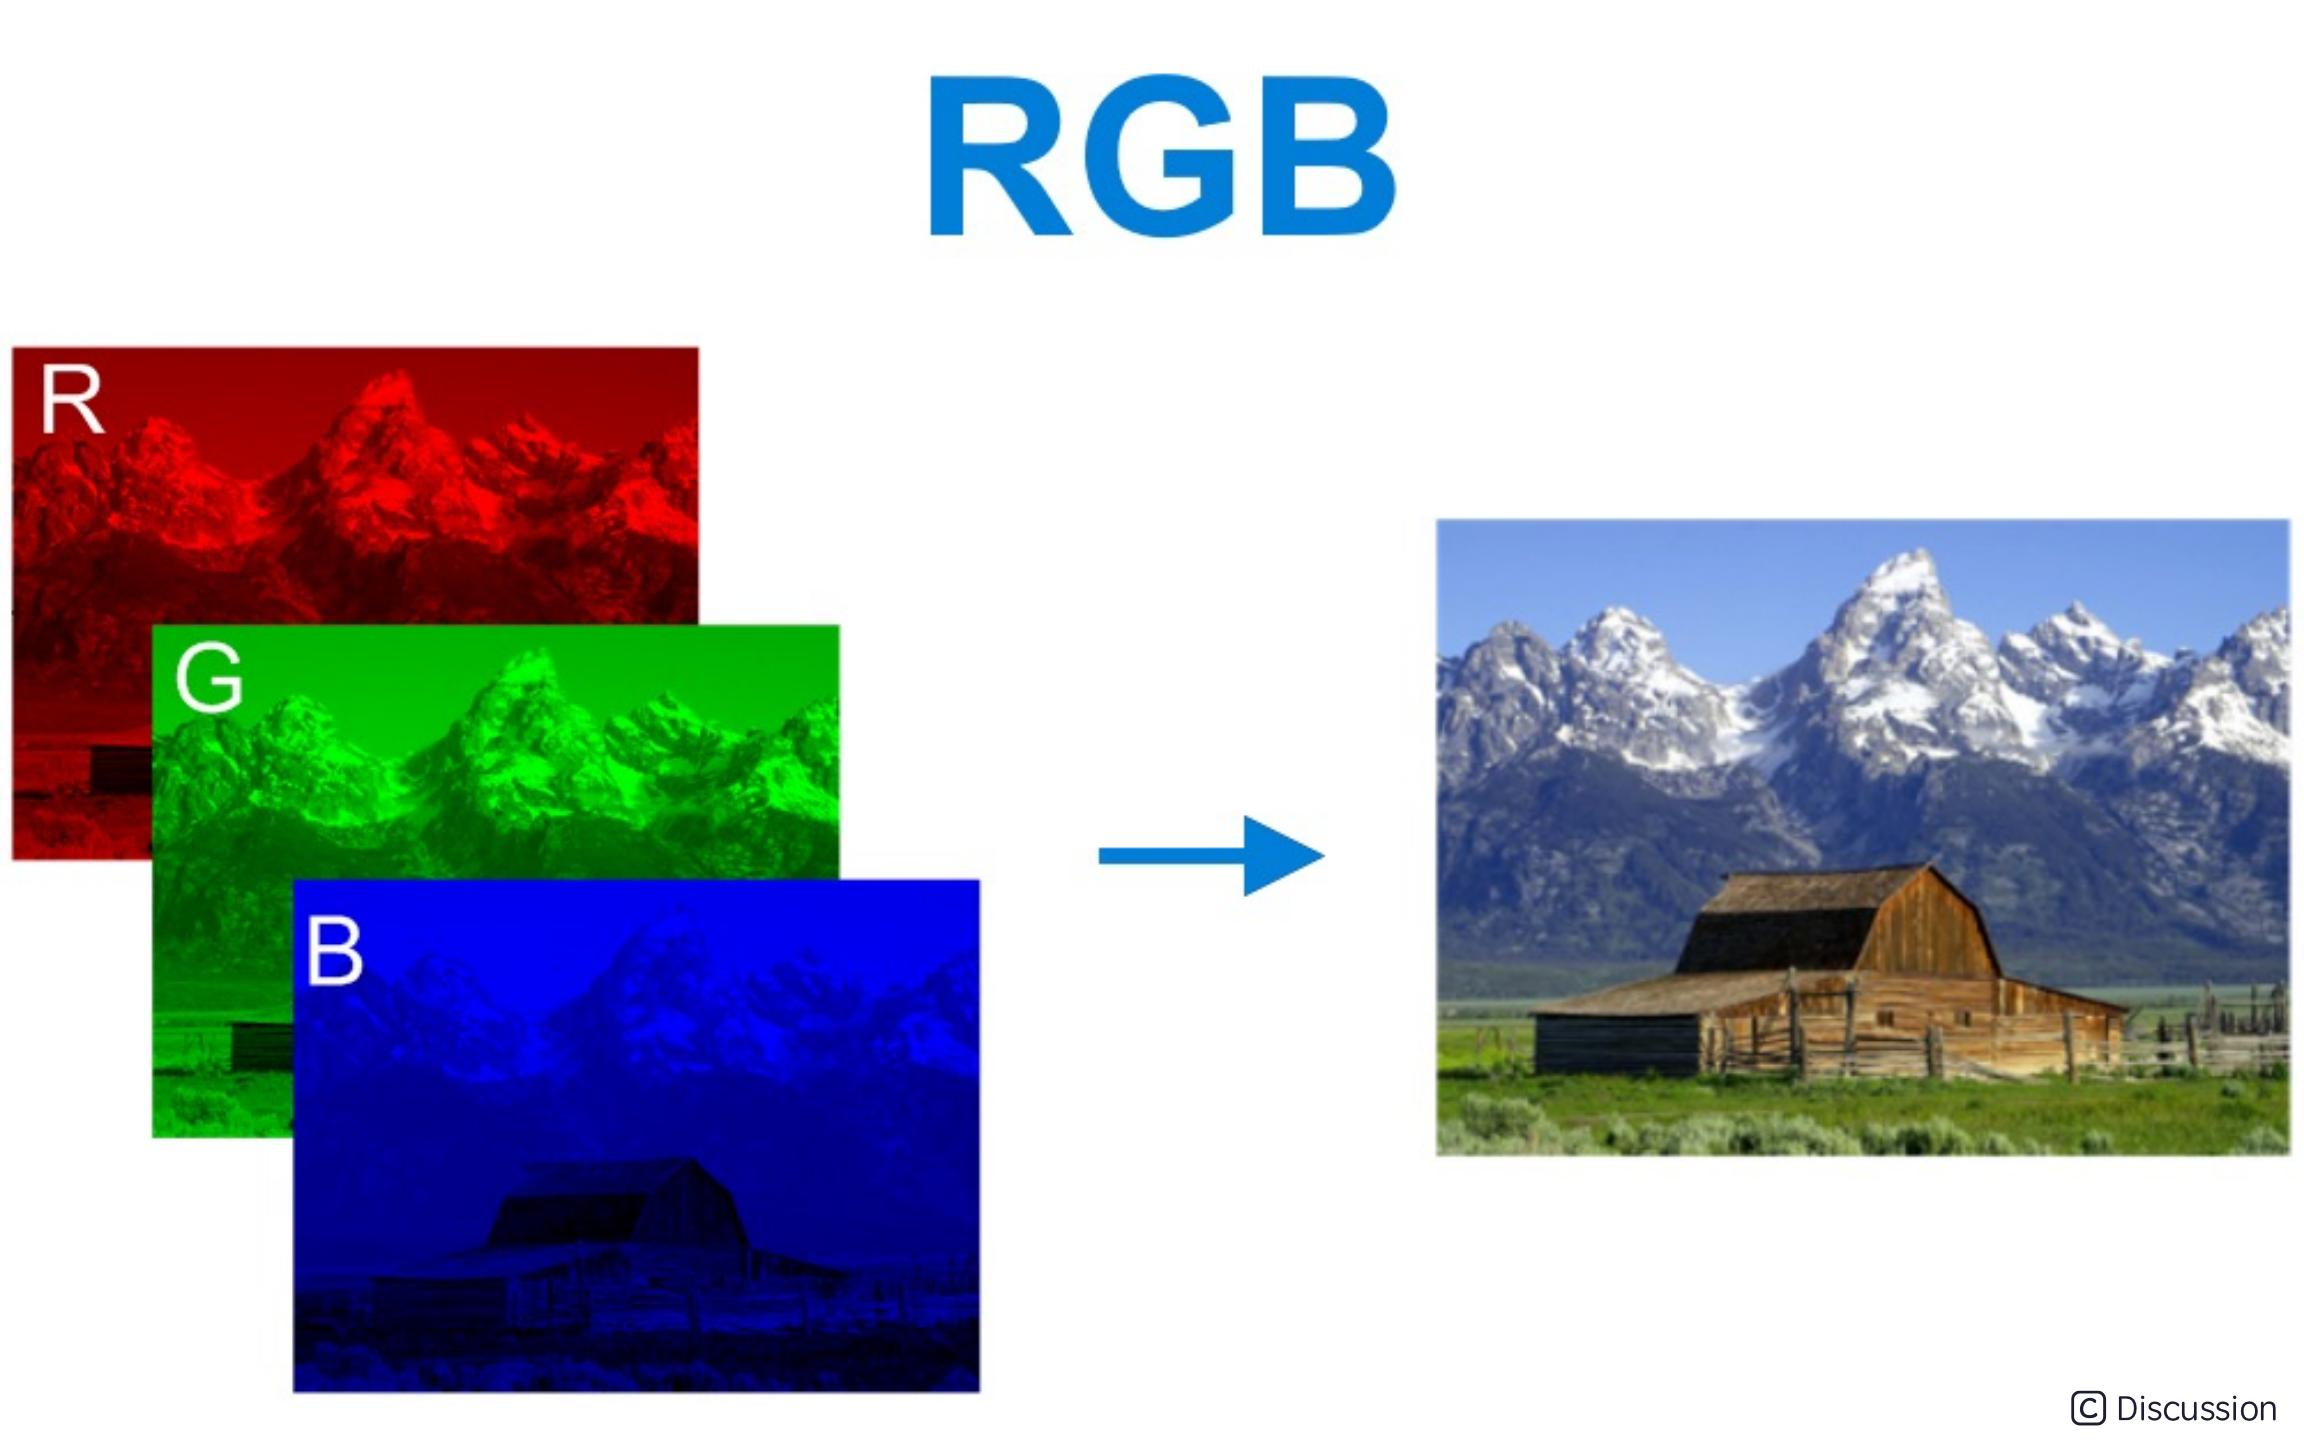
    - **HSV:** 색상(Hue), 채도(Saturation), 명도(Value) 기준

- **텐서**  
: 다차원 데이터 배열을 통칭하는 용어
    - **0차원:** 스칼라 (숫자 하나)
    - **1차원:** 벡터 (숫자 나열된 형태)
    - **2차원:** 행렬 (예: `28 × 28`)
    - **3차원 이상:** 다차원 구조 (예: `28 × 28 × 1`)

#### 1-2. CNN의 개념

- 인식 방법 차이
    - **사람:** 중요한 특징에 집중하고 종합해 판단
    - **컴퓨터:** 픽셀 단위로 구분
    - 픽셀 정보 학습의 문제점: 2차원 공간 구조의 활용 x

#### 1-3. MLP와 CNN의 구조

- **MLP** = `FC Layer + ... + FC Layer`
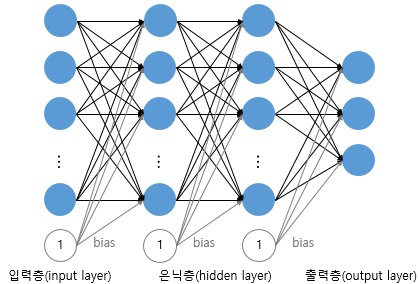
    - 입력 데이터 → FC Layer 전달해 학습
- **CNN** = `(Conv + Pool) + ... + Flatten + FC Layer + ... + FC Layer`
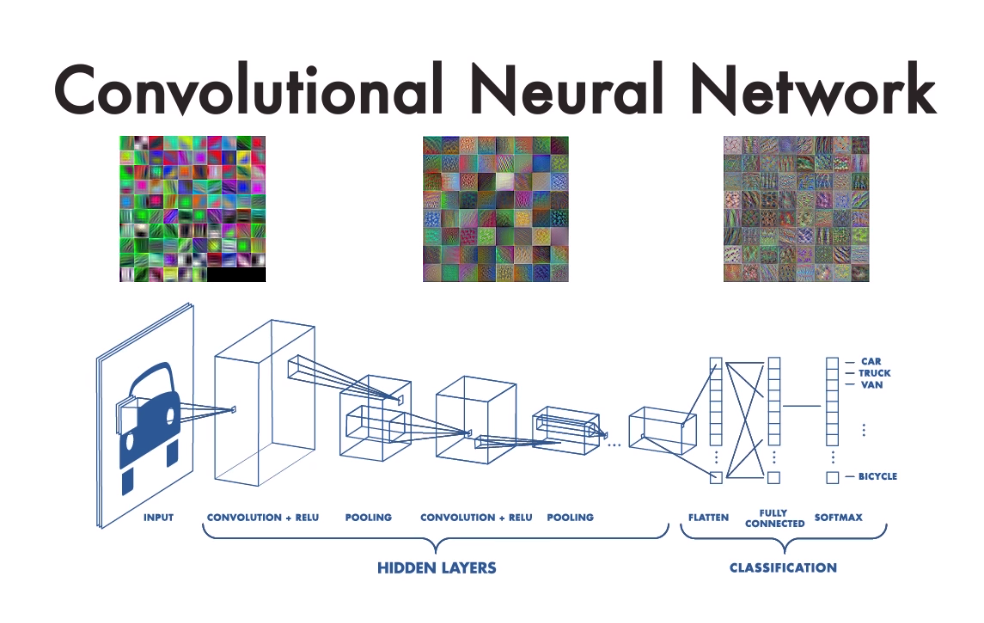
    - 입력 데이터 → Conv, Pool로 학습 → FC Layer 전달
    - 구조
    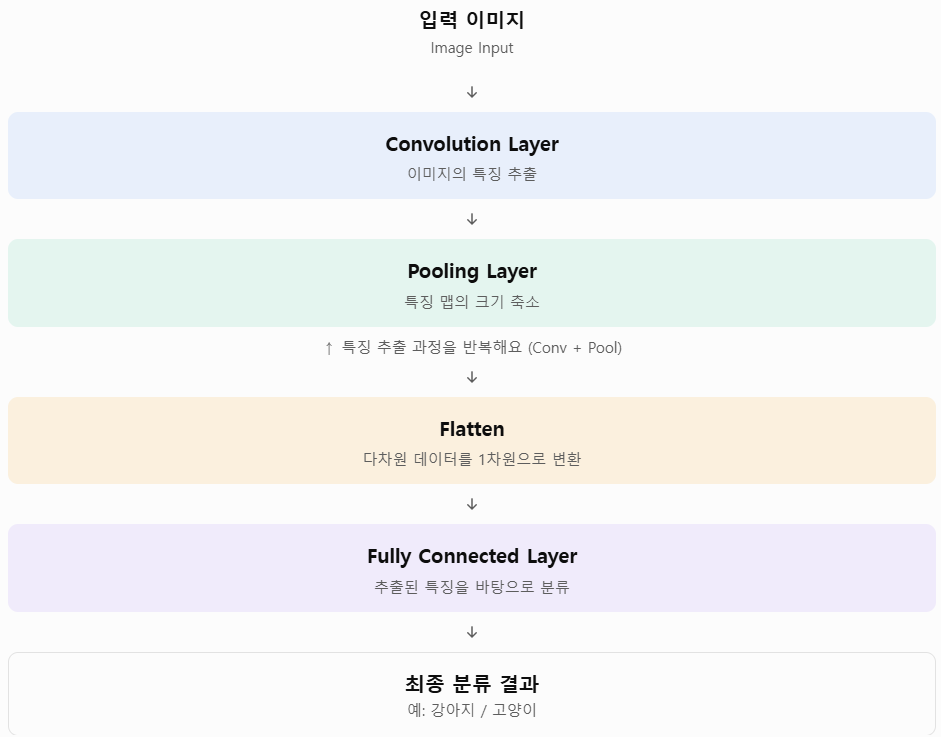
        - **Convolution Layer:** 필터로 이미지 특징 추출
        - **Pooling Layer:** 특징 맵의 크기 축소, 연산량 감소
        - **Flatten:** 특징 맵 1차원으로 변환
        - **FC Layer:** 추출한 특징을 분류

- **MLP**의 한계
    - **변화에 취약:** 위치, 크기, 회전 등 변화에 따라 성능이 저하됨
    - **파라미터 폭발:** 완전 연결 구조라 파라미터 급증 → 과적합 위험, 학습 속도 느려짐
    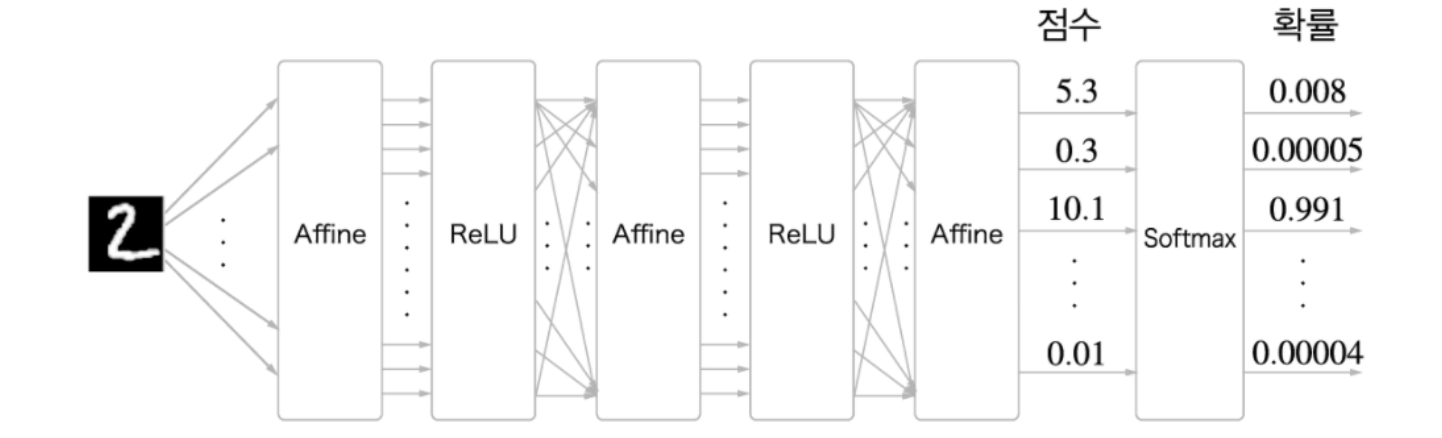
    - **공간 정보 손실:** 1차원으로 펼치면서 2차원 공간 구조 유지 x

- **CNN**의 해결 방법
    - **필터 반복 적용:** 특징이 어디에 있든 탐지
    - **부분 연결 구조:** + 가중치 공유로 파라미터 수 감소
    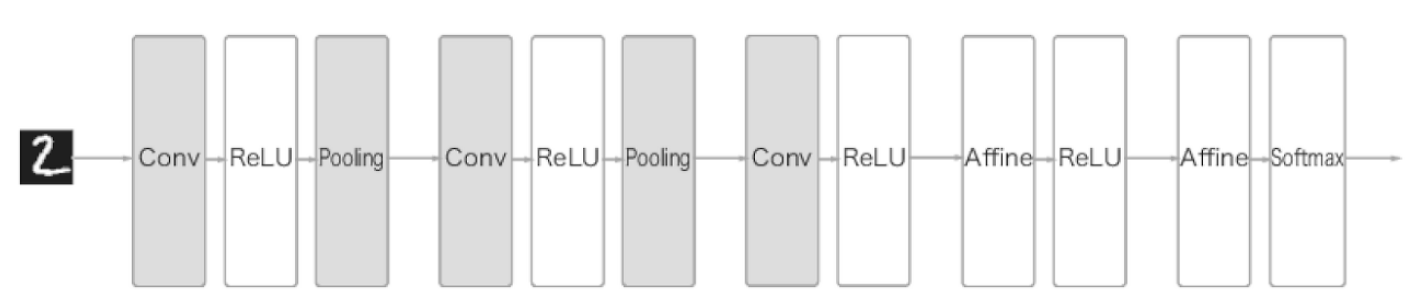
    - **다차원 구조 유지:**  H × W × C 형태의 다차원 구조로 학습 → Flatten
    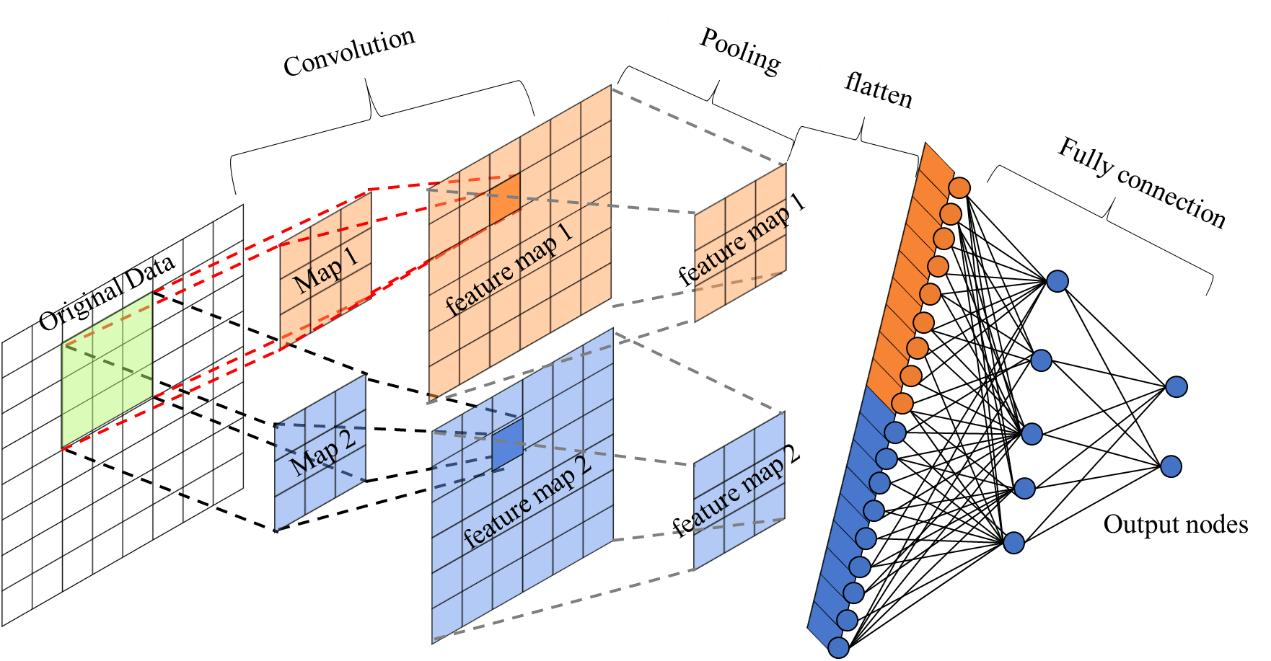

#### 1-4. 합성곱과 풀링

- **Convolution Layer**  
: 필터로 이미지를 훑으면서 특징을 추출하고 학습하는 계층
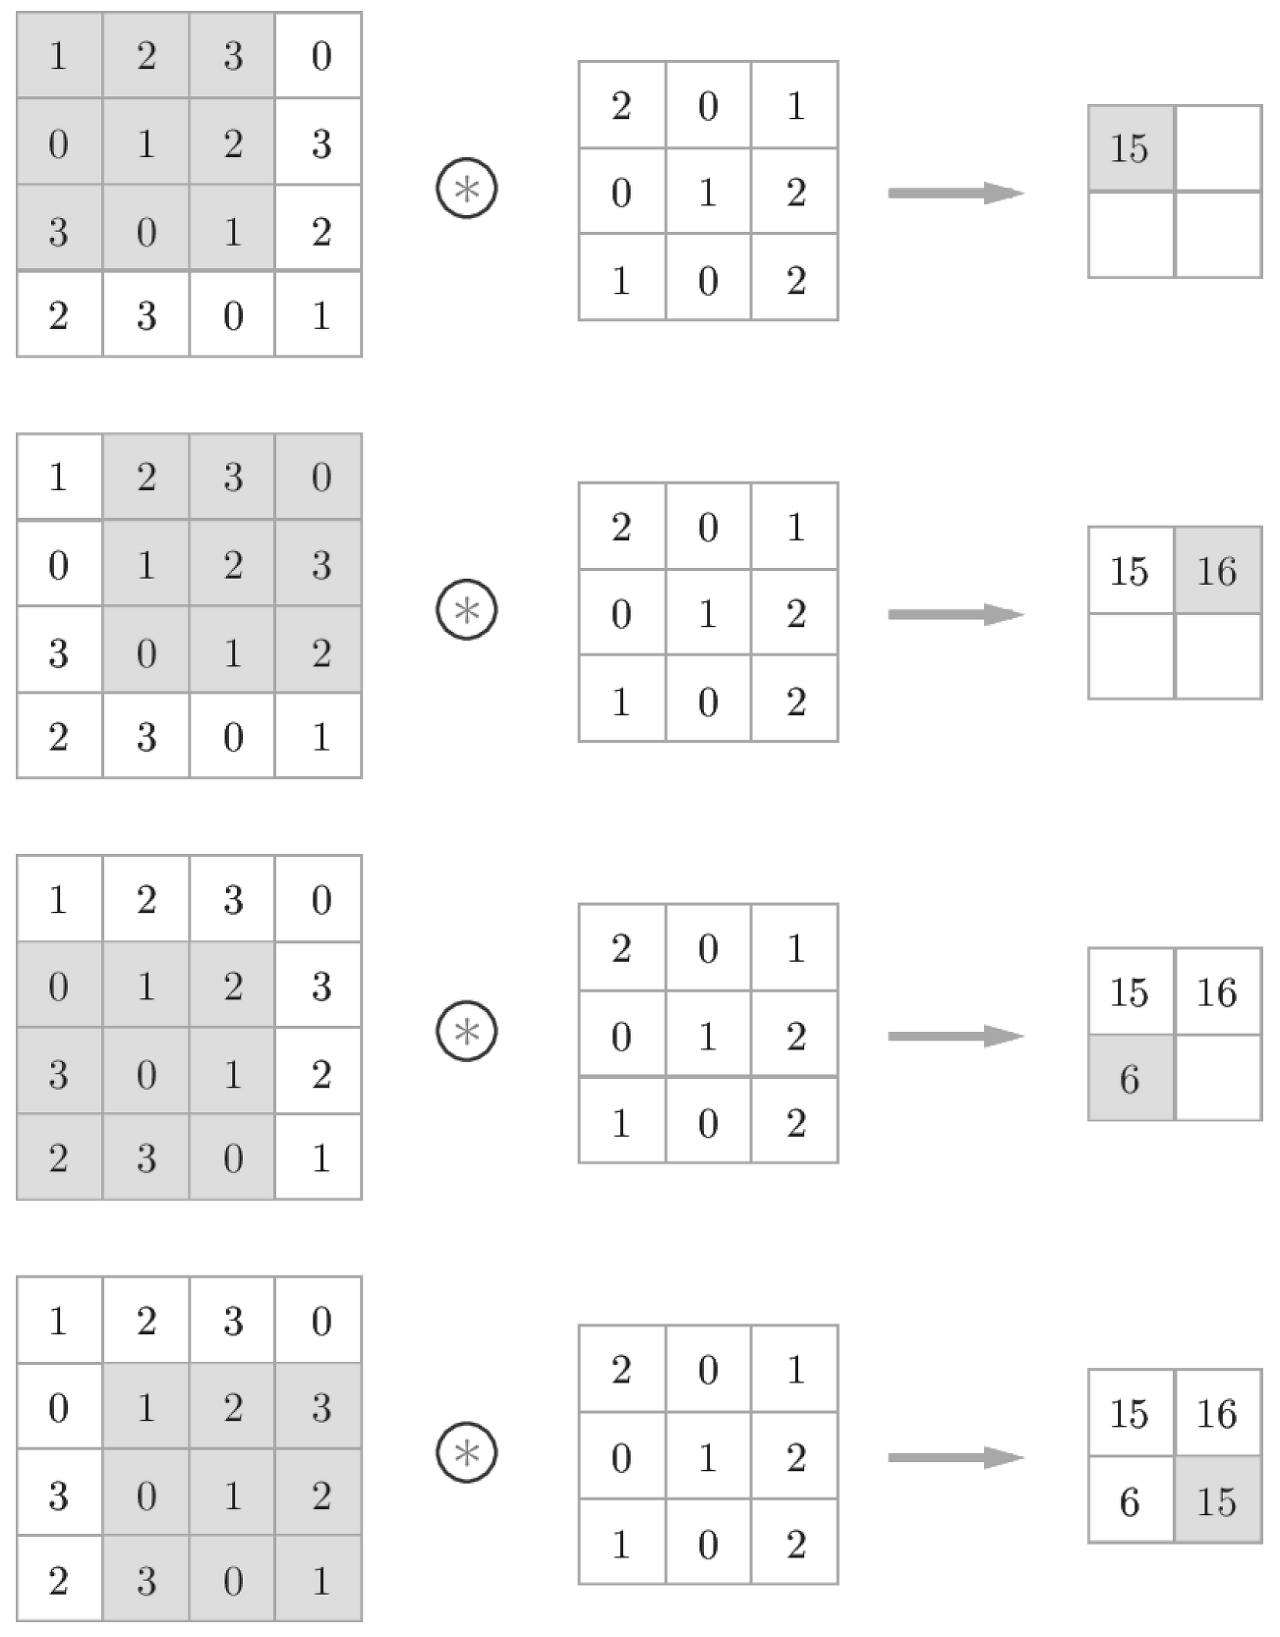
    - 과정
    1. 필터를 이미지 위로 슬라이딩
    2. 각 위치에서 같은 자리끼리 곱한 뒤 모두 더함
    3. 결과를 Feature Map에 저장

- 커널과 필터 차이
    - **커널:** 패턴을 추출하는 2차원 가중치 행렬
    - **필터:** 여러 커널의 묶음

- **Feature Map**  
: Convolution 연산의 결과 데이터
    - 필터가 특징에 강하게 반응할수록 값이 커짐
    - Feature Map 개수 = 필터 개수
    - RGB에 필터 1개 적용 → Feature Map 1개로 출력

- **Padding**  
: 이미지 가장자리에 픽셀을 추가하는 방법 
    - 주로 0 추가 = Zero Padding
    - 크기가 지나치게 작아지는 것 방지
    - 가장자리의 특징도 학습 가능

- **Stride**  
: 필터가 한 번에 이동하는 거리
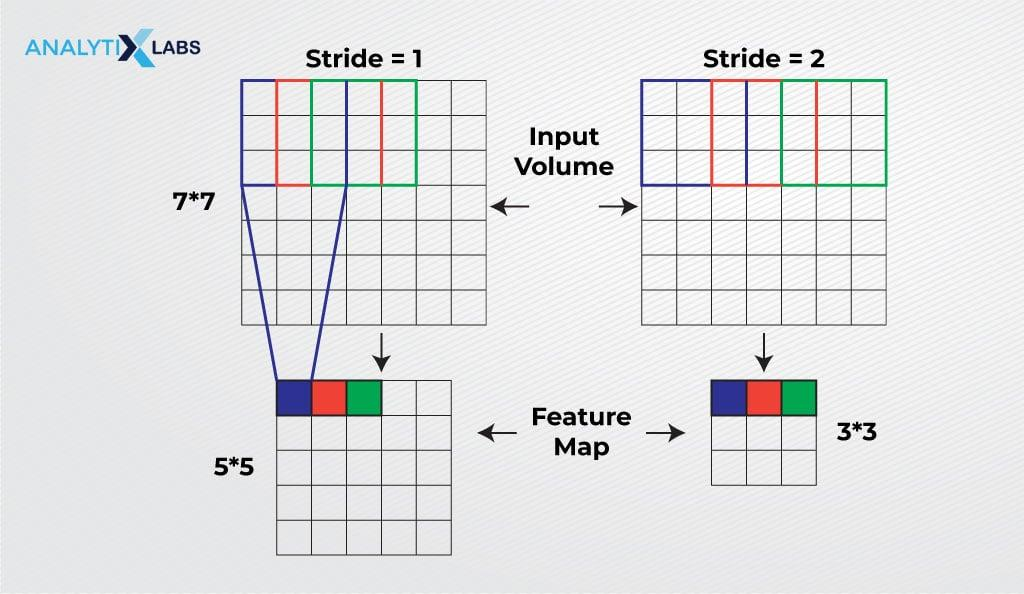
    - 1: 한 칸 이동, 여러 위치 세밀하게 확인, Feature Map이 큼
    - 2: 두 칸 이동, 연산 감소, Feature Map이 작아짐
    - 특징이 세밀한지와 연산 효율 결정

- **Pooling**  
: 위치 변화에 대한 민감도를 낮추는 연산
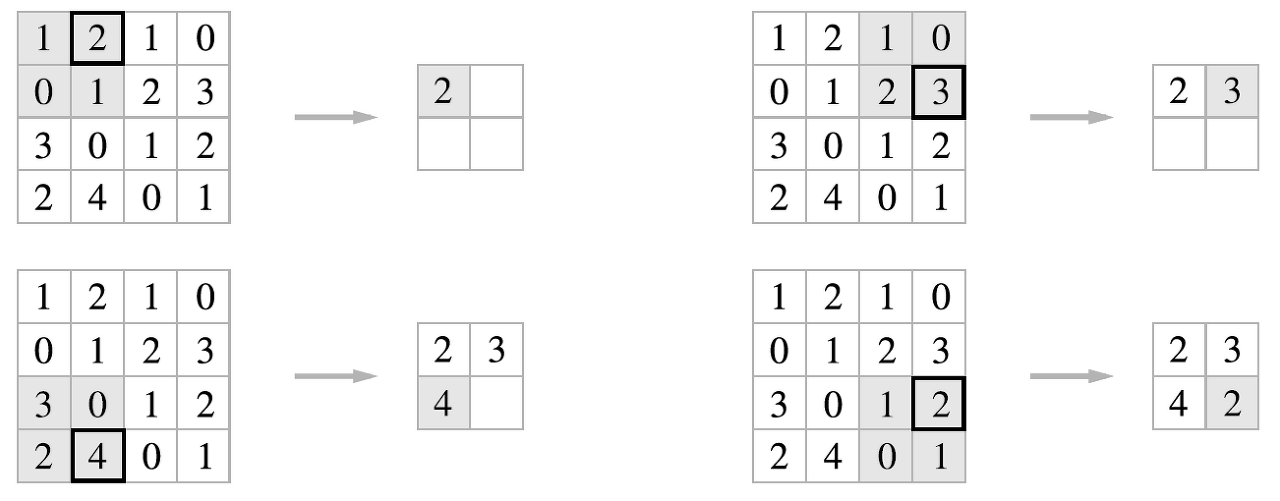
    - 영역 설정 → 값을 하나로 요약
    - 공간적 크기, 데이터 양 축소 가능
    - **Max Pooling:** 영역 안 최댓값 선택
    - **Average Pooling:** 영역의 평균 계산
    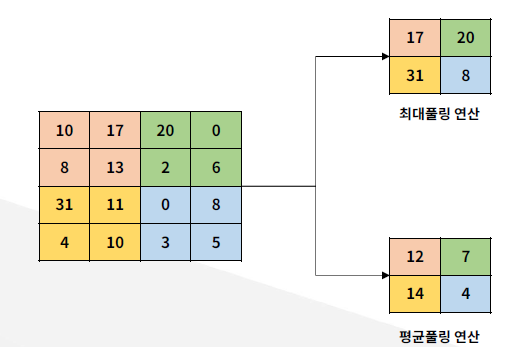
    - 장점: 계산량 감소, 작은 위치 변화에 강함, 과적합 방지에 도움, 노이즈 영향 완화
    - 단점: 세부 정보와 정확한 위치 정보 손실

#### 1-5. 대표적인 CNN 아키텍처

- **AlexNet (2012)**  
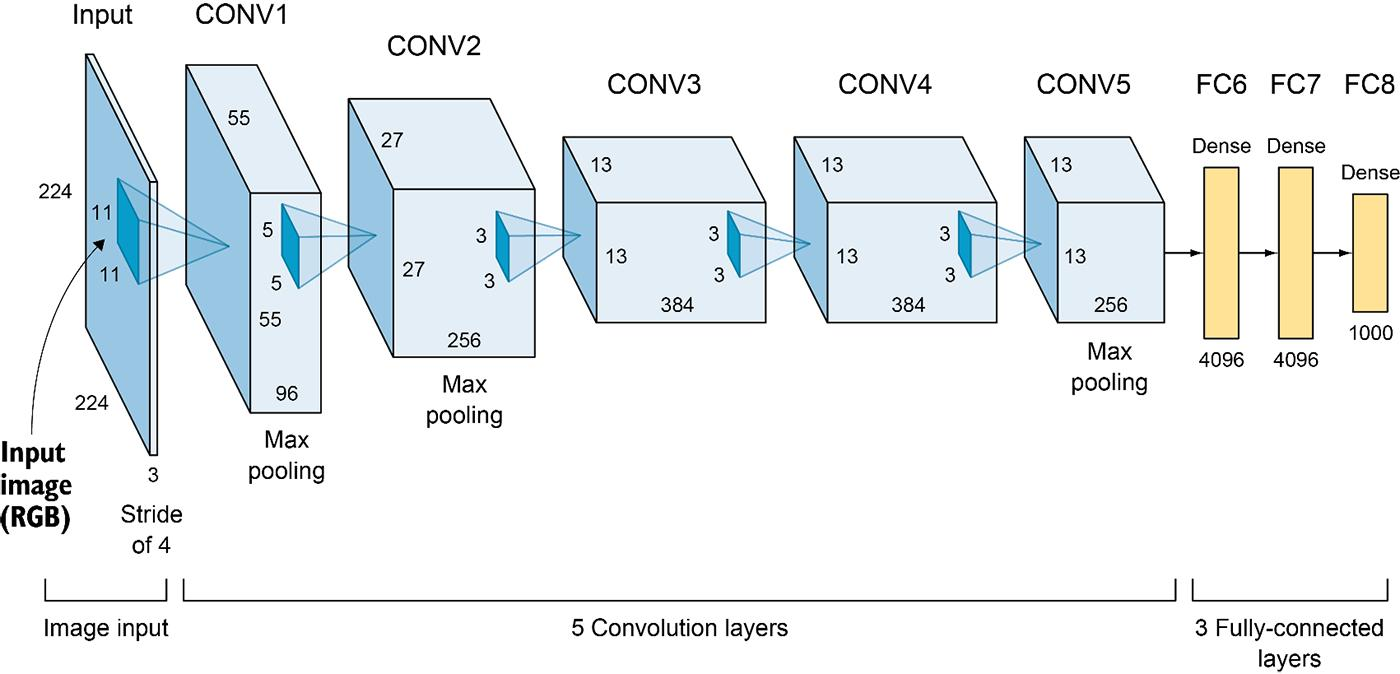
    - **구조:** Conv 5개 + FC 3개 (총 8층)
    - **주요 기술:** ReLU, 다중 GPU, 드롭아웃, 데이터 증강, LRN

- **VGGNet (2014)**  
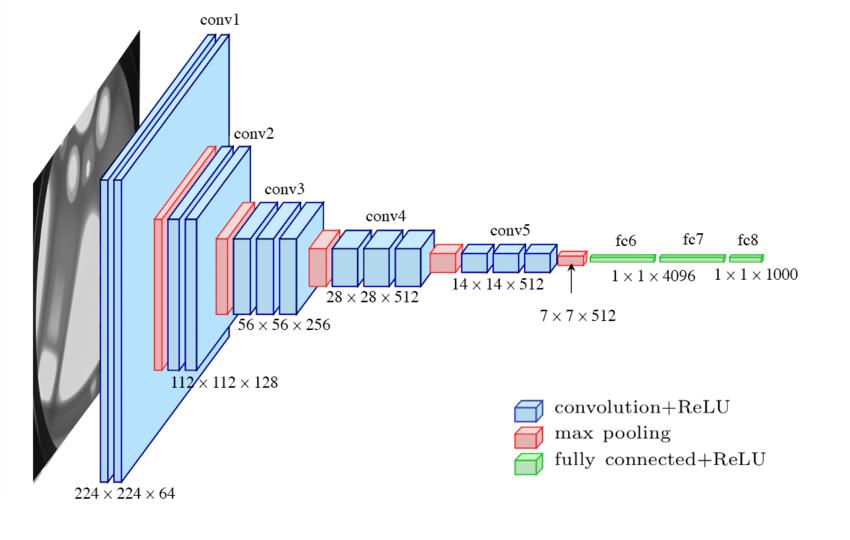
    - **구조:** VGG16 = Conv 13개 + FC 3개 (총 16층)
    - **주요 특징:** `3 × 3` 작은 필터 반복 사용, 깊은 네트워크, 일관된 구조

- **ResNet (2015)**  
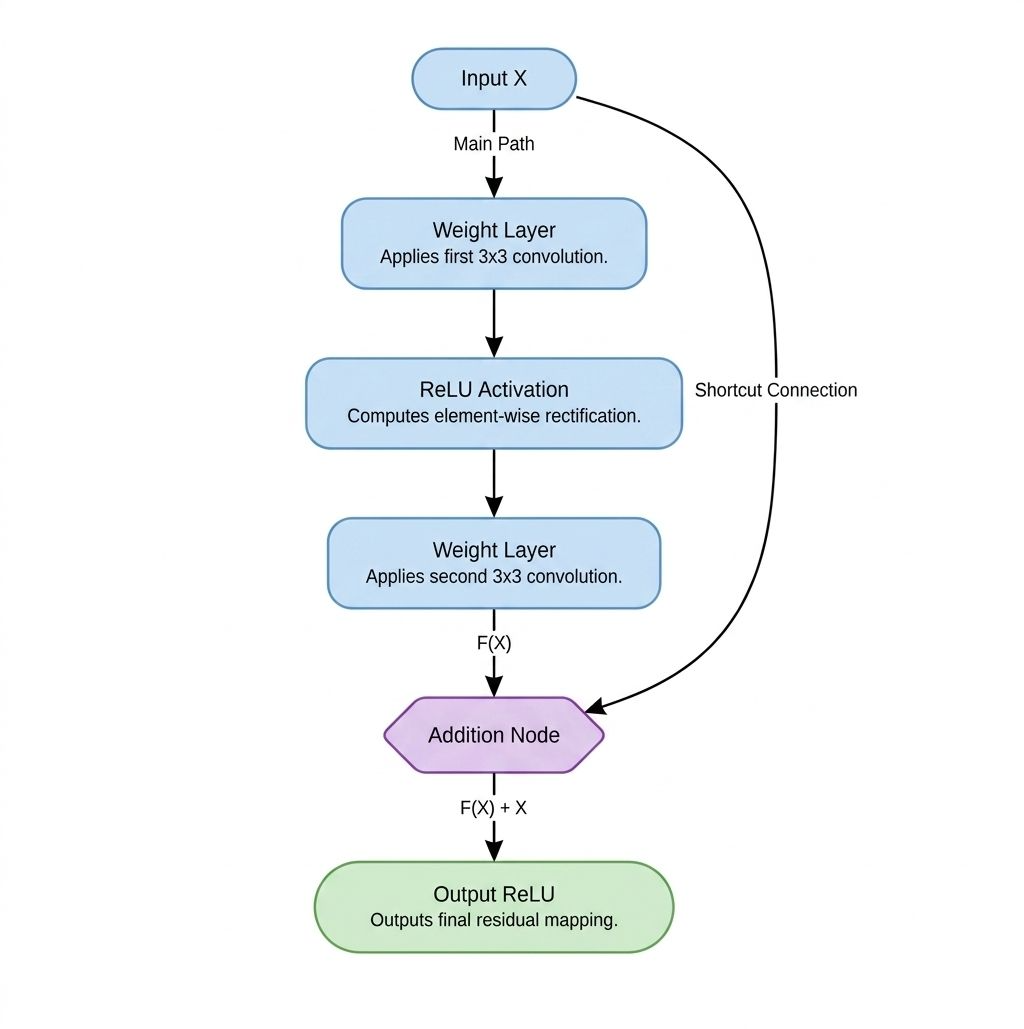
    - 잔차 연결 구조 도입
    - **Skip Connection:** 입력을 중간 계층 건너뛰고 뒤쪽 계층으로 직접 전달
    - 계층 통과 결과 + 처음 입력 정보를 다음 계층으로 전달

---

### 2. 이미지 딥러닝 응용

#### 2-1. 이미지 분류

- **이미지 분류**  
: 이미지를 사전 정의된 클래스 중 하나로 분류

| 모델 | 특징 | 주의사항 |
| --- | --- | --- |
| AlexNet | 단순한 초기 CNN | 작은 데이터셋, 개념 학습용 |
| VGG | 깊은 구조 | 계산량, 메모리 요구 높음 |
| ResNet | Skip Connection으로 매우 깊은 구조 가능 | 과적합 주의 |
| ViT | 패치 기반 입력 처리 | 대규모 데이터 필요 |

#### 2-2. 객체 탐지

- **객체 탐지**  
: 이미지 안 개별 객체의 **종류와 위치**를 함께 예측
    - **Bounding Box:** 객체를 둘러싸는 사각형
    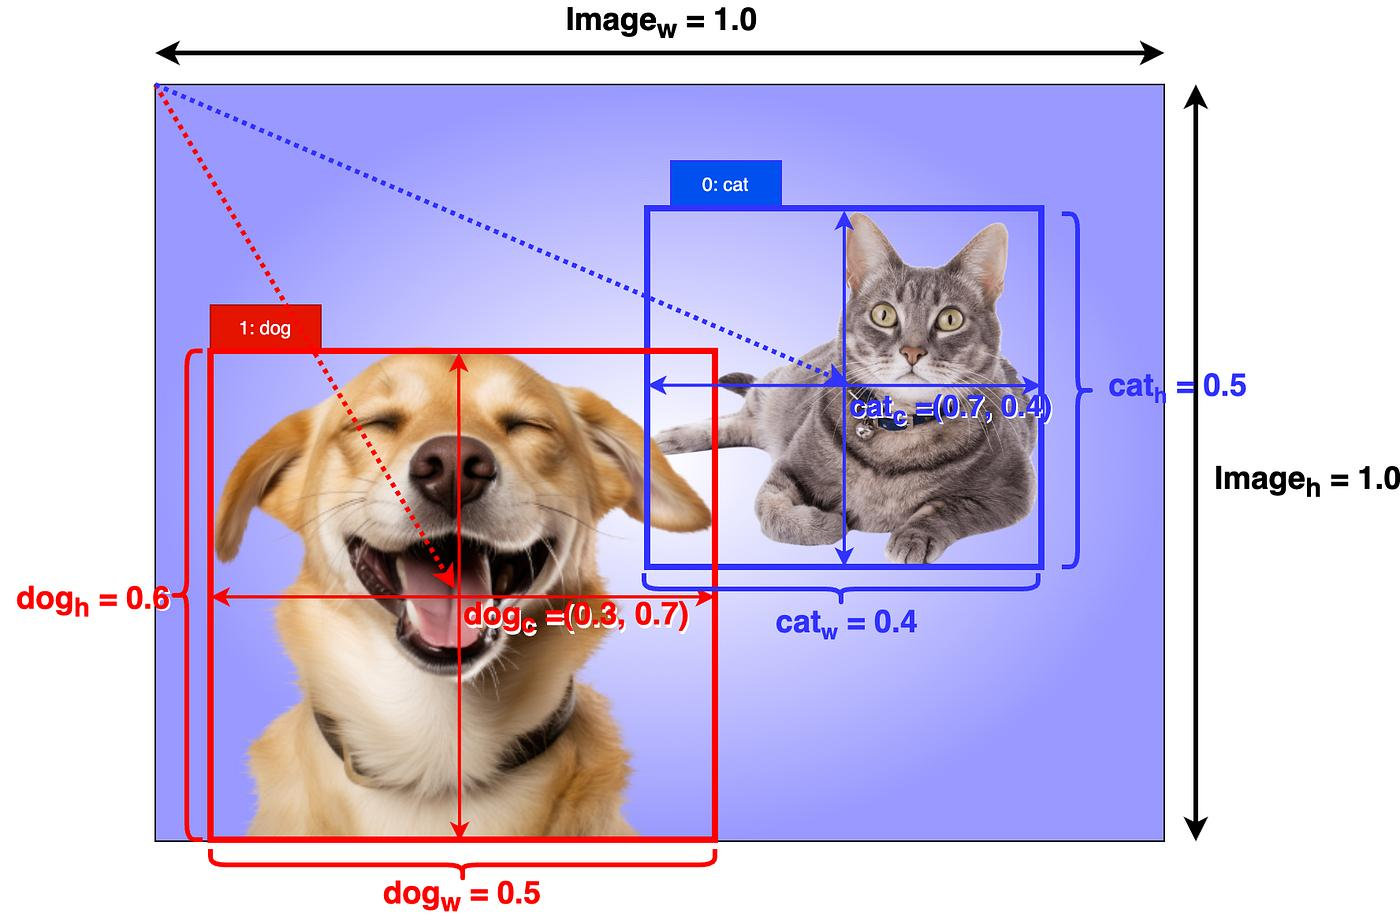
        - 중심 좌표 (x, y), 너비 `w`, 높이 `h`로 표현
    - 모델 적용 방식
        - **Classification Head:** 객체의 종류 예측
        - **Regression Head:** 객체의 위치 예측
        - **대표 모델:** `YOLO, Faster R-CNN, SSD`

#### 2-3. 이미지 캡셔닝

- **이미지 캡셔닝**  
: 이미지의 내용을 자연어 문장으로 표현
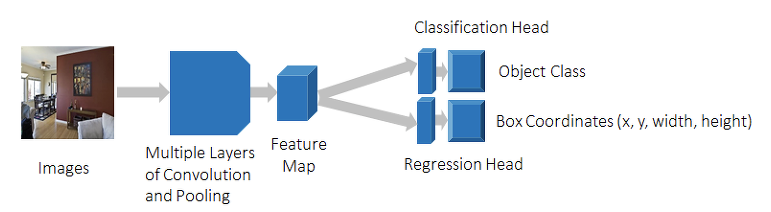
    - 모델 적용 방식
        - **CNN:** 이미지 특징 추출
        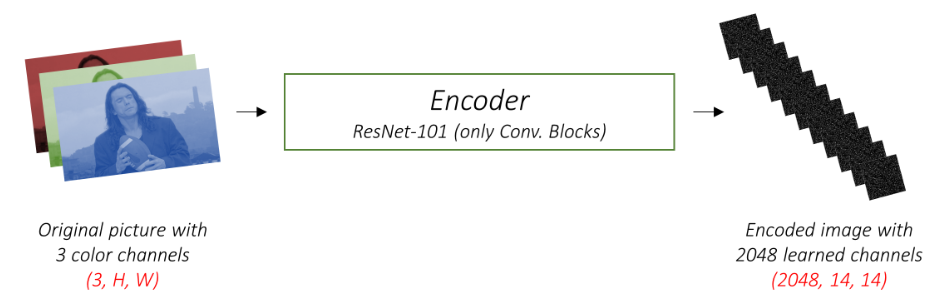
        - **RNN:** 문장 생성
        - **Attention:** 중요한 영역에 가중치
        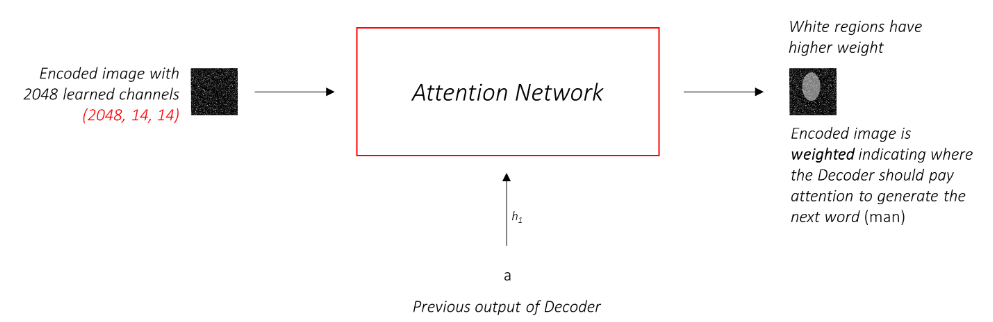

---

### 3. RNN (순환 신경망)

#### 3-1. 순차 데이터

- **순차 데이터**  
: 순서가 의미를 갖고, 순서를 바꾸면 정보가 달라지는 데이터
    - **시간적:** 시간 순
    - **비시간적:** 위치, 순번 기준
    - **수치형:** 값의 크기, 거리에 의미 o
    - **범주형:** 값의 크기, 거리에 의미 x
    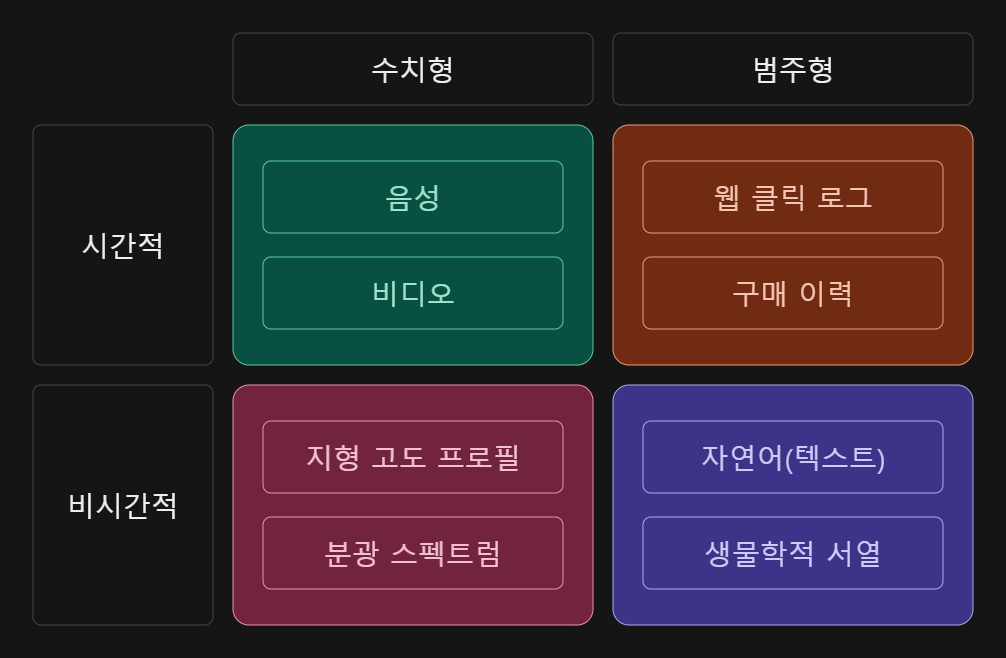

- 정형 데이터 vs 순차 데이터
    - **정형 데이터:** 순서 바꿔도 의미 그대로
    - **순차 데이터:** 순서 의존성 O

#### 3-2. RNN의 구조와 원리

- **RNN**  
: 은닉층에 **순환 구조** 존재
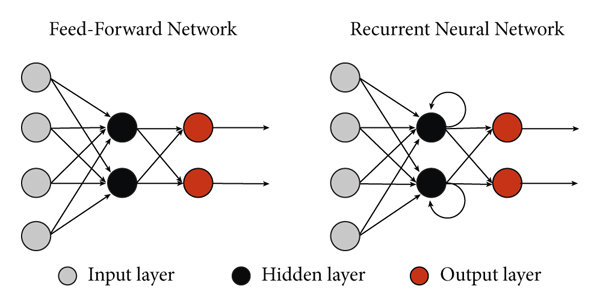

- **구조**
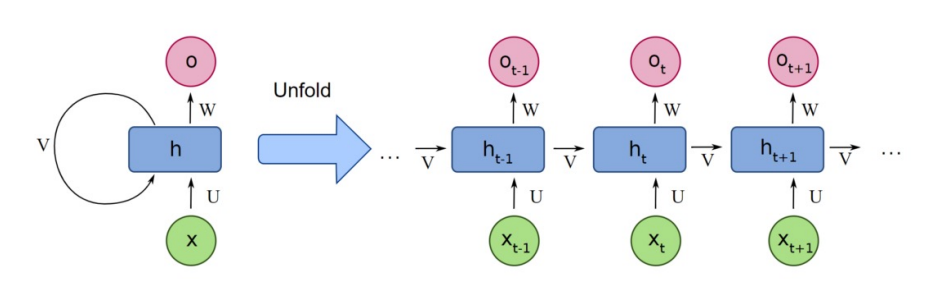
    - **입력층 $x$:** 시점 $t$의 입력 받음
    - **은닉층 $h$:** 현재 입력과 이전 은닉 상태로 만드는 곳
    - **출력층 $o$:** 은닉 상태로 만드는 시점 $t$의 결과 내보냄
    - **가중치:** 입력 $U$, 순환 $V$, 출력 $W$

- **원리**
    - **은닉 상태 계산:** $h_t = \tanh(Ux_t + Vh_{t-1} + b)$
    - **출력 계산:** $o_t = f(Wh_t + c)$
    - **tanh:** 값을 `-1 ~ 1`로 제한, 비선형성 추가
    - **$f$:** 이진 분류는 시그모이드, 다중 분류는 소프트맥스

- **아키텍처**
    - **One to Many:** 이미지 캡셔닝  
    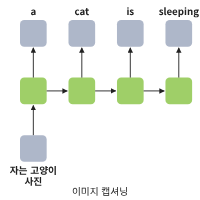
    - **Many to One:** 스팸 메일 분류, 감성 분류  
    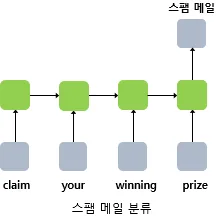
    - **Many to Many:** 
        - 동기식: 매 시점 출력, 객체 태깅  
        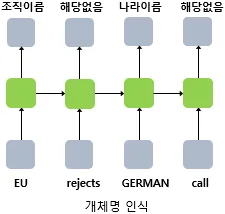
        - 비동기식: 입력 다 읽고 출력, 기계 번역, 요약

#### 3-3. RNN의 한계

- **BPTT**  
: 시간을 거슬러 오차를 전파해 기울기를 계산하는 방법
    - 연쇄 법칙에 따라 시점마다 (활성화 함수 미분값) × (순환 가중치) 곱해짐
    - 같은 $V$ 모든 시점 공유 → 등비수열 형태

- **기울기 소실**  
: 과거로 갈수록 기울기가 0에 가까워지는 현상
    - $V$가 1보다 작을 때
    - 먼 과거 정보가 학습에 반영 x

- **기울기 폭주**  
: 과거로 갈수록 기울기가 매우 커지는 현상
    - $V$이 1보다 클 때
    - 오차 진동, 심하면 NaN 발생, 학습 중단

- **느린 훈련 시간**
    - 시퀀스 길수록 오래 걸림
    - 메모리 부담이 큼
    - 시점 순서대로 계산

- **장기 의존성 문제**  
: 관련 정보가 멀리 떨어져 있을수록 관계를 학습하지 못하는 문제
    - 해결: `LSTM, GRU` 필요

---

### 4. LSTM & GRU

#### 4-1. LSTM & GRU

- **게이트**  
: 정보를 얼마나 통과시킬지 정하는 구성

#### 4-2. LSTM

- **LSTM**  
: 기억을 두 상태로 나눠 관리하는 모델
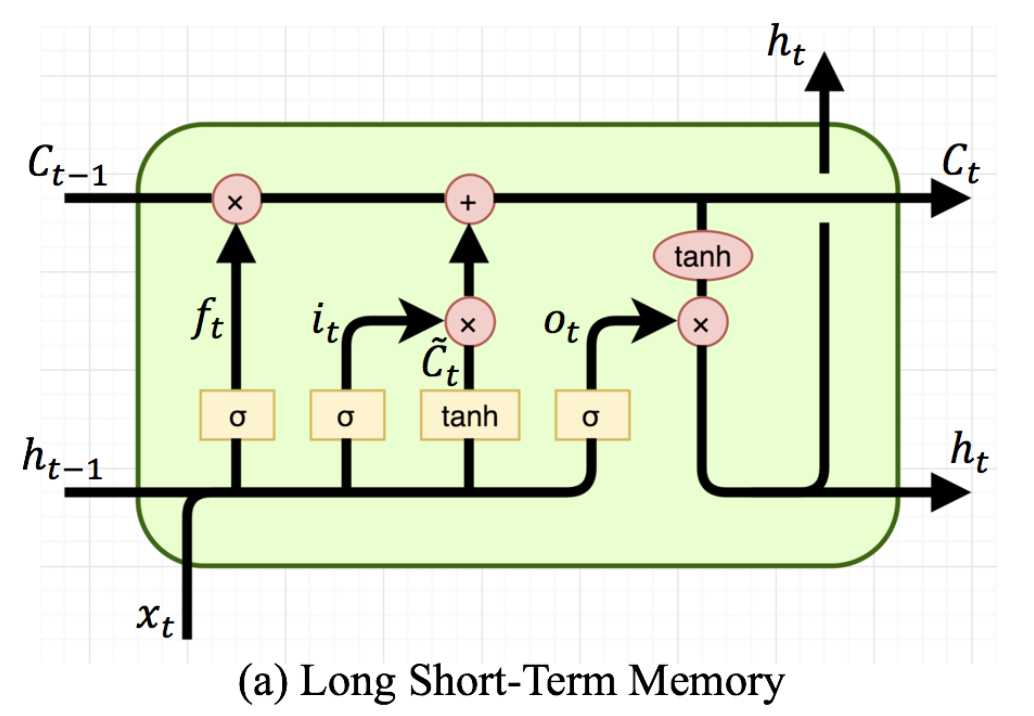
    - **셀 상태:** 장기 기억
    - **은닉 상태:** 단기 기억, 출력

- **게이트 3개**
    - **Forget Gate:** 무엇을 잊을지
        - $f_t = \sigma(W_f \cdot [h_{t-1}, x_t] + b_f)$
    - **Input Gate:** 무엇을 새로 기억할지
        - $i_t = \sigma(W_i \cdot [h_{t-1}, x_t] + b_i)$
        - $\tilde{C}_t = \tanh(W_C \cdot [h_{t-1}, x_t] + b_C)$
    - **Final memory cell:** 기억 업데이트
        - $C_t = f_t \odot C_{t-1} + i_t \odot \tilde{C}_t$
        - 곱셈이 아닌 덧셈으로 이어짐   
    - **Output Gate:** 무엇을 내보낼지
        - $o_t = \sigma(W_o \cdot [h_{t-1}, x_t] + b_o)$
        - $h_t = o_t \odot \tanh(C_t)$

- **장점:** 기울기 소실 완화, 장기 의존성 학습 가능
- **단점:** 계산량/메모리가 많음, 여전히 순서대로 계산, 소실을 없애지는 x

#### 4-3. GRU

- **GRU**  
: LSTM 구조를 단순하게 줄인 모델
    - 은닉 상태 + 게이트 2개

- **게이트 2개**
    - **Update Gate:** 과거 기억 : 새 정보 비율 결정 (Forget + Input 통합)
        - $h_t = (1 - z_t) \odot h_{t-1} + z_t \odot \tilde{h}_t$
    - **Reset Gate:** 과거 기억을 얼마나 무시할지 결정

- **장점:** 단순하고 학습이 빠름, 데이터가 적어도 안정적, LSTM과 비슷한 성능
- **단점:** 장기 기억과 출력 분리 x, 정교함 떨어짐

#### 4-4. LSTM vs GRU

- 정교함(LSTM)과 효율(GRU)의 선택
- 성능 비슷

---

### 5. Seq2Seq

#### 5-1. Seq2Seq의 구조

- **Seq2Seq**  
: 입력 시퀀스를 받아 다른 시퀀스를 출력하는 모델
    - 입력과 출력의 길이 달라도 됨
    - 활용: 기계 번역, 챗봇, 문서 요약, 음성 인식
    - 내부 셀 주로 `LSTM` or `GRU` 사용
    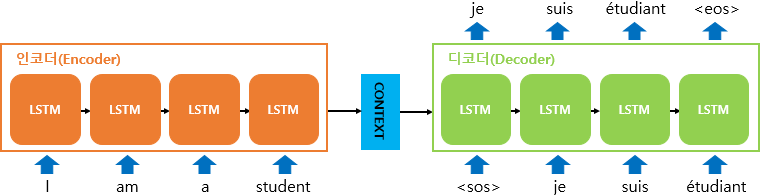

- **인코더**  
: 입력 문장 순서대로 읽어 컨텍스트 벡터로 압축
    1. 단어로 토큰화
    2. 임베딩
    3. LSTM 셀에 한 단어씩 입력
    4. 마지막 은닉 상태 → 디코더로 전달

- **디코더**  
: 컨텍스트 벡터로 출력 문장 한 단어씩 생성
    1. 컨텍스트 벡터를 첫 은닉 상태로 받음
    2. 시작 신호 <sos> 첫 입력
    3. softmax로 다음 단어 선택
    4. 예측한 단어를 다음 입력으로
    5. 종료 신호 <eos>로 생성 종료

- **컨텍스트 벡터**  
: 문장 요약 벡터
    - 인코더와 디코더를 잇는 통로
    - 크기 = 하이퍼파라미터 (256, 512, 1024)
    - 디코더의 은닉 상태 크기도 같은 값
    - 크면 계산량 증가, 과적합 위험
    - 작으면 빠르지만 정보 다 담지 x

#### 5-2. Seq2Seq의 한계

- **병목 현상**  
: 정보를 컨텍스트 벡터에 압축하며 손실되는 현상
    - 긴 문장일수록 손실이 큼
    - 앞 단어는 점점 희미 → 장기 의존성 문제